In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r'C:\Users\malik\Downloads\data-analysis-2023-labs-master\data-analysis-2023-labs-master\input\olympics-economics.csv'
)

df['gold'] = pd.to_numeric(df['gold'], errors='coerce')
df['silver'] = pd.to_numeric(df['silver'], errors='coerce')
df['bronze'] = pd.to_numeric(df['bronze'], errors='coerce')
df['total'] = pd.to_numeric(df['total'], errors='coerce')
df['gdp'] = pd.to_numeric(df['gdp'], errors='coerce')
df['population'] = pd.to_numeric(df['population'], errors='coerce')

In [ ]:
#Bu yerda medal olgan va olmagan mamlakatlarning GDP ko‘rsatkichlarini taqqoslaymiz.
df['medal_status'] = np.where(
    df['total'] > 0, 'Medal olgan', 'Medal olmagan'
)

df.groupby('medal_status')['gdp'].agg(
    ['count', 'mean', 'std', 'min', 'max']
)

,count,mean,std,min,max
medal_status,,,,,
Medal olgan,90,24478.053556,25547.857382,1014.21,103684.88


In [ ]:
#Bu orqali iqtisodiy darajasi turlicha bo‘lgan mamlakatlarning medal natijalarini taqqoslaymiz.
df['gdp_group'] = pd.cut(
    df['gdp'],
    bins=3,
    labels=['Past GDP', 'O‘rta GDP', 'Yuqori GDP']
)

df.groupby('gdp_group', observed=True)['total'].agg(
    ['count', 'mean', 'std', 'sum', 'max']
)

,count,mean,std,sum,max
gdp_group,,,,,
Past GDP,68,7.264706,12.563412,494,91
O‘rta GDP,16,24.562500,21.490986,393,65
Yuqori GDP,6,25.166667,49.507239,151,126


In [ ]:
#u guruhlash aholi soni turlicha bo‘lgan mamlakatlarning medal natijalarini ko‘rsatadi.
df['population_group'] = pd.qcut(
    df['population'],
    q=3,
    labels=['Kam aholi', 'O‘rta aholi', 'Ko‘p aholi'],
    duplicates='drop'
)

df.groupby('population_group', observed=True)['total'].agg(
    ['count', 'mean', 'std', 'min', 'max']
)

,count,mean,std,min,max
population_group,,,,,
Kam aholi,30,4.066667,3.929845,1,20
O‘rta aholi,30,8.333333,10.674925,1,53
Ko‘p aholi,30,22.200000,29.759264,1,126


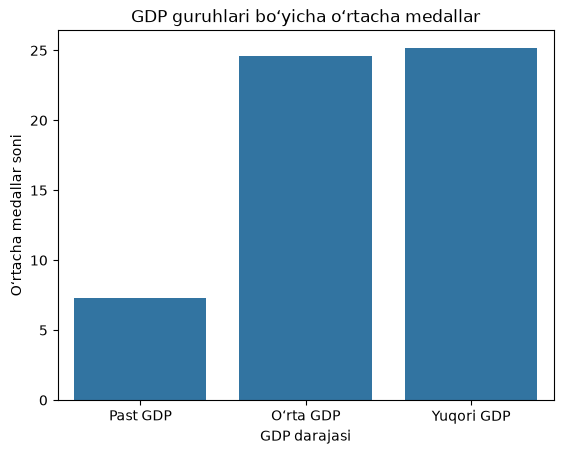

In [5]:
sns.barplot(
    data=df,
    x='gdp_group',
    y='total',
    errorbar=None
)

plt.title('GDP guruhlari bo‘yicha o‘rtacha medallar')
plt.xlabel('GDP darajasi')
plt.ylabel('O‘rtacha medallar soni')
plt.show()

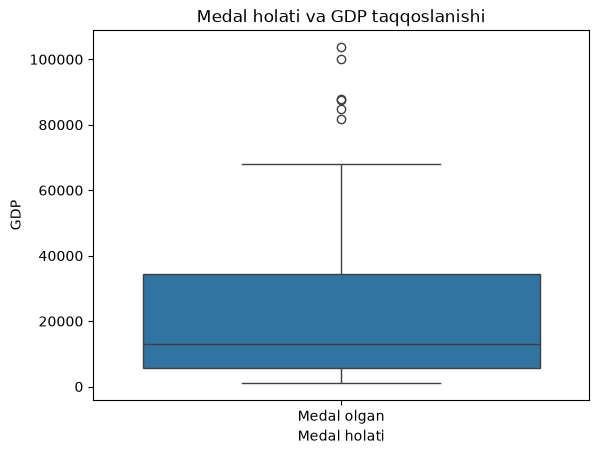

In [6]:
sns.boxplot(
    data=df,
    x='medal_status',
    y='gdp'
)

plt.title('Medal holati va GDP taqqoslanishi')
plt.xlabel('Medal holati')
plt.ylabel('GDP')
plt.show()

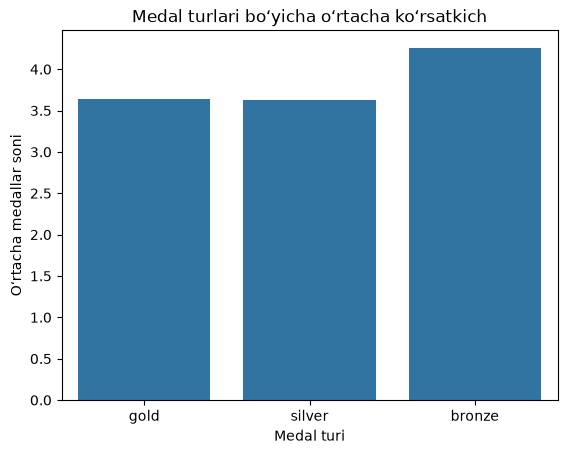

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

df_medals = df.melt(
    id_vars=['country'],
    value_vars=['gold', 'silver', 'bronze'],
    var_name='medal_type',
    value_name='medal_count'
)

sns.barplot(
    data=df_medals,
    x='medal_type',
    y='medal_count',
    errorbar=None
)

plt.title('Medal turlari bo‘yicha o‘rtacha ko‘rsatkich')
plt.xlabel('Medal turi')
plt.ylabel('O‘rtacha medallar soni')
plt.show()

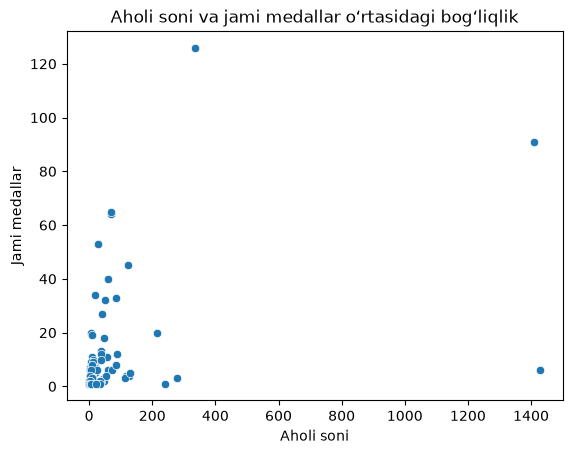

In [9]:
sns.scatterplot(
    data=df,
    x='population',
    y='total'
)

plt.title('Aholi soni va jami medallar o‘rtasidagi bog‘liqlik')
plt.xlabel('Aholi soni')
plt.ylabel('Jami medallar')
plt.show()

In [10]:
corr_df = df[['gdp', 'total']].dropna()

x = corr_df['gdp']
y = corr_df['total']

x_mean = x.mean()
y_mean = y.mean()

numerator = ((x - x_mean) * (y - y_mean)).sum()

denominator = np.sqrt(
    ((x - x_mean) ** 2).sum() *
    ((y - y_mean) ** 2).sum()
)

r = numerator / denominator

print("Korrelyatsiya:", r)

Korrelyatsiya: 0.34794157444147755


In [11]:
corr_check = corr_df['gdp'].corr(corr_df['total'])

print("Qo‘lda hisoblangan:", r)
print("Pandas orqali:", corr_check)

Qo‘lda hisoblangan: 0.34794157444147755
Pandas orqali: 0.34794157444147733


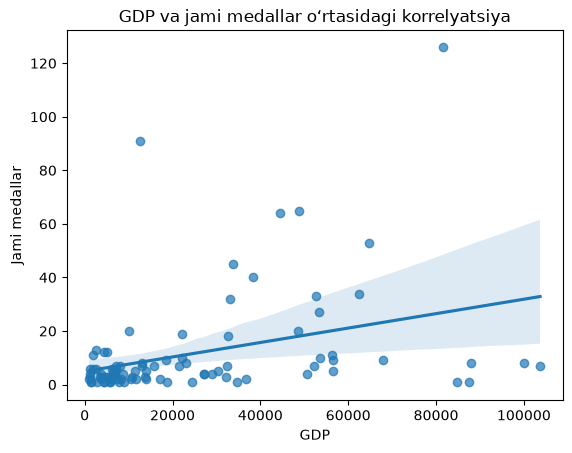

In [12]:
sns.regplot(
    data=corr_df,
    x='gdp',
    y='total',
    scatter_kws={'alpha': 0.7}
)

plt.title('GDP va jami medallar o‘rtasidagi korrelyatsiya')
plt.xlabel('GDP')
plt.ylabel('Jami medallar')
plt.show()